# 2 · Controlo de qualidade: deteção de anomalias numa câmara de frio
**AgroNet Forward · AI Insights for Agro**

**Pergunta de negócio:** *como saber, **a tempo**, que a câmara está a falhar, sem ser acordado por falsos alarmes?*

Neste notebook comparamos **três abordagens**, da mais simples à mais "inteligente", e medimos três coisas
que importam a quem gere uma câmara: **avarias apanhadas**, **quanto tempo demorámos** e **falsos alarmes**.

> ⚠️ **Dados sintéticos** (21 dias, leituras de 5 em 5 minutos) com 4 avarias simuladas. São poucos eventos:
> os números servem para **compreender os métodos**, não como medida de desempenho real.

> 💡 **No Google Colab:** *Ficheiro → Carregar para a sessão* e carregue o CSV desta pasta `dados/`. Se não o fizer, o notebook gera automaticamente os mesmos dados.

## 0 · Preparação

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

# --- Gerador de reserva -------------------------------------------
# Se o ficheiro CSV não estiver na pasta (p.ex. no Google Colab), os dados
# são gerados aqui, com a mesma semente => exatamente os mesmos dados.
# (Pode ignorar este código; o notebook começa na secção 1.)

def gerar_camara(seed=7, dias=21):
    rng = np.random.default_rng(seed)
    passo = 5  # minutos
    n = dias * 24 * 60 // passo
    ts = pd.date_range("2026-09-01 00:00", periods=n, freq=f"{passo}min")
    minutos = np.arange(n) * passo

    setpoint = 4.0
    temp = np.full(n, setpoint)
    # Ciclo normal do compressor (oscilação suave ~ 40 min)
    temp += 0.6 * np.sin(2 * np.pi * minutos / 40)
    # Descongelação: de 6 em 6 horas, subida curta e previsível (NORMAL!)
    ciclo = minutos % (6 * 60)
    defrost = (ciclo < 25)
    temp += np.where(defrost, 2.2 * np.sin(np.pi * ciclo / 25), 0)
    # Aberturas de porta (normais): picos curtos em horário de trabalho
    porta = np.zeros(n, dtype=int)
    for d in range(dias):
        for _ in range(rng.integers(5, 10)):
            h = rng.uniform(7, 18)
            ini = int((d * 24 * 60 + h * 60) / passo)
            dur = int(rng.integers(1, 3))
            if ini + dur < n:
                porta[ini:ini + dur] = 1
    atraso = np.convolve(porta, np.array([0.5, 1.0, 0.8, 0.5, 0.3, 0.15]))[:n]
    temp += 1.3 * atraso
    temp += rng.normal(0, 0.12, n)

    anomalia = np.zeros(n, dtype=int)
    tipo = np.array([""] * n, dtype=object)

    # Anomalia A (dia 6): deriva lenta - compressor a perder eficiência (~14 h)
    ini = int((5 * 24 * 60 + 9 * 60) / passo)
    dur = int(14 * 60 / passo)
    temp[ini:ini + dur] += np.linspace(0, 4.5, dur)
    temp[ini + dur:ini + dur + 24] += np.linspace(4.5, 0, 24)
    anomalia[ini:ini + dur + 12] = 1
    tipo[ini:ini + dur + 12] = "deriva_compressor"

    # Anomalia B (dia 11): sensor encravado (valor constante ~ 5 h)
    ini = int((10 * 24 * 60 + 14 * 60) / passo)
    dur = int(5 * 60 / passo)
    temp[ini:ini + dur] = temp[ini] + rng.normal(0, 0.005, dur)
    anomalia[ini:ini + dur] = 1
    tipo[ini:ini + dur] = "sensor_encravado"

    # Anomalia C (dia 16): porta deixada aberta (~ 90 min)
    ini = int((15 * 24 * 60 + 12 * 60) / passo)
    dur = int(90 / passo)
    temp[ini:ini + dur] += np.linspace(0, 7, dur)
    temp[ini + dur:ini + dur + 36] += np.linspace(7, 0, 36)
    porta[ini:ini + dur] = 1
    anomalia[ini:ini + dur + 12] = 1
    tipo[ini:ini + dur + 12] = "porta_aberta"

    # Anomalia D (dia 19): corte de energia (~ 3 h) - subida rápida
    ini = int((18 * 24 * 60 + 2 * 60) / passo)
    dur = int(3 * 60 / passo)
    temp[ini:ini + dur] += np.linspace(0, 9, dur)
    temp[ini + dur:ini + dur + 48] += np.linspace(9, 0, 48)
    anomalia[ini:ini + dur + 24] = 1
    tipo[ini:ini + dur + 24] = "corte_energia"

    hum = np.clip(85 - 2.0 * (temp - 4) + rng.normal(0, 1.5, n), 40, 99)
    return pd.DataFrame({
        "timestamp": ts,
        "temp_c": temp.round(2),
        "humidade_pct": hum.round(1),
        "porta_aberta": porta,
        "anomalia_real": anomalia,
        "tipo_anomalia": tipo,
    })

## 1 · Os dados

In [2]:
CAMINHO = "../dados/camara_frio.csv"
if os.path.exists(CAMINHO):
    df = pd.read_csv(CAMINHO, parse_dates=["timestamp"])
else:
    print("CSV não encontrado -> a gerar os dados na hora.")
    df = gerar_camara()

df["tipo_anomalia"] = df["tipo_anomalia"].fillna("")
print(df.shape)
df.head()

(6048, 6)


,timestamp,temp_c,humidade_pct,porta_aberta,anomalia_real,tipo_anomalia
0,2026-09-01 00:00:00,4.05,82.5,0,0,
1,2026-09-01 00:05:00,5.60,82.0,0,0,
2,2026-09-01 00:10:00,6.61,78.5,0,0,
3,2026-09-01 00:15:00,6.40,77.5,0,0,
4,2026-09-01 00:20:00,5.19,82.7,0,0,


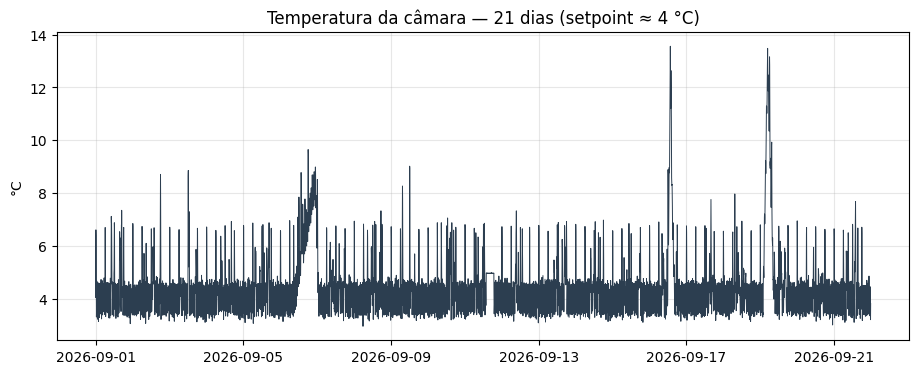

In [3]:
fig, ax = plt.subplots()
ax.plot(df.timestamp, df.temp_c, lw=0.7, color="#2C3E50")
ax.set_ylabel("°C")
ax.set_title("Temperatura da câmara — 21 dias (setpoint ≈ 4 °C)")
plt.show()

Já se percebem **três tipos de subida** (ou "movimento"), e só alguns são problemas:

| O que se vê | O que é | Normal? |
|---|---|---|
| Pequenas subidas **de 6 em 6 horas** | ciclo de descongelação | ✅ normal |
| Picos curtos **durante o dia** | abertura da porta | ✅ normal |
| Subidas grandes e/ou prolongadas | avaria | ❌ **queremos alertar** |

O desafio: um alarme simples **não distingue** o normal do problema. Para a demonstração (e **só porque os dados
são simulados**), sabemos onde estão as avarias reais (zonas a vermelho). Na vida real não temos essa coluna.

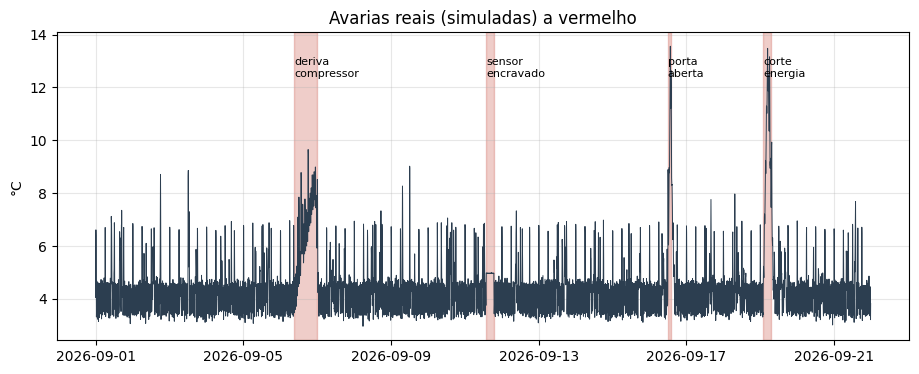

In [4]:
df["minuto_ciclo"] = (df.timestamp.dt.hour * 60 + df.timestamp.dt.minute) % 360  # posição no ciclo de 6 h

def segmentos(mask):
    """Lista (início, fim) de cada troço contínuo de True."""
    m = np.asarray(mask).astype(int)
    d = np.diff(np.r_[0, m, 0])
    return list(zip(np.where(d == 1)[0], np.where(d == -1)[0] - 1))

reais = segmentos(df.anomalia_real == 1)

fig, ax = plt.subplots()
ax.plot(df.timestamp, df.temp_c, lw=0.7, color="#2C3E50")
for ini, fim in reais:
    ax.axvspan(df.timestamp[ini], df.timestamp[fim], color="#C0392B", alpha=0.25)
    ax.text(df.timestamp[ini], df.temp_c.max() * 0.97, df.tipo_anomalia[ini].replace("_", "\n"),
            fontsize=8, va="top")
ax.set_ylabel("°C")
ax.set_title("Avarias reais (simuladas) a vermelho")
plt.show()

## 2 · Como medir o resultado
Para cada método contamos: **quantas avarias** foram detetadas, o **atraso médio** (minutos entre o início da
avaria e o 1.º alerta) e os **falsos alarmes** (alertas sem avaria).

In [5]:
def avaliar(alerta, nome, tolerancia=12):
    alerta = np.asarray(alerta).astype(bool)
    detetados, atrasos = 0, []
    for ini, fim in reais:
        idx = np.where(alerta[ini:fim + tolerancia + 1])[0]
        if len(idx):
            detetados += 1
            atrasos.append(idx[0] * 5)
    falsos = sum(1 for a_i, a_f in segmentos(alerta)
                 if not any(a_f >= ini and a_i <= fim + tolerancia for ini, fim in reais))
    return {"método": nome, "avarias detetadas": f"{detetados}/{len(reais)}",
            "atraso médio (min)": round(np.mean(atrasos)) if atrasos else None,
            "falsos alarmes": falsos}

resultados = []

## 3 · Método A — limite fixo (o que a maioria dos sistemas faz)
"*Se a temperatura passar de X °C, alerta.*" Experimente dois limiares.

In [6]:
for limite in (8, 7):
    resultados.append(avaliar(df.temp_c > limite, f"A. Limite fixo > {limite} °C"))
pd.DataFrame(resultados).set_index("método")

,avarias detetadas,atraso médio (min),falsos alarmes
método,,,
A. Limite fixo > 8 °C,3/4,122,4
A. Limite fixo > 7 °C,3/4,67,13


**Dilema clássico:** com limite mais alto (8 °C) há poucos falsos alarmes, mas **avisa tarde**; com limite mais
baixo (7 °C) avisa mais cedo, mas **dispara com a porta e a descongelação**. E há uma avaria que **nenhum limite
apanha**: o sensor encravado (marca sempre o mesmo valor, parece "tudo normal").

## 4 · Método B — "perfil esperado" + regra de linha plana
Em vez de um valor fixo, aprendemos **o que é normal em cada momento do ciclo de 6 h** (usando os primeiros
5 dias, sem avarias) e alertamos quando a temperatura se afasta **de forma persistente** desse perfil.
Acrescentamos uma regra simples para o sensor encravado: *"desvio-padrão da última hora quase zero"*.

É **IA leve**: estatística + bom senso, totalmente explicável.

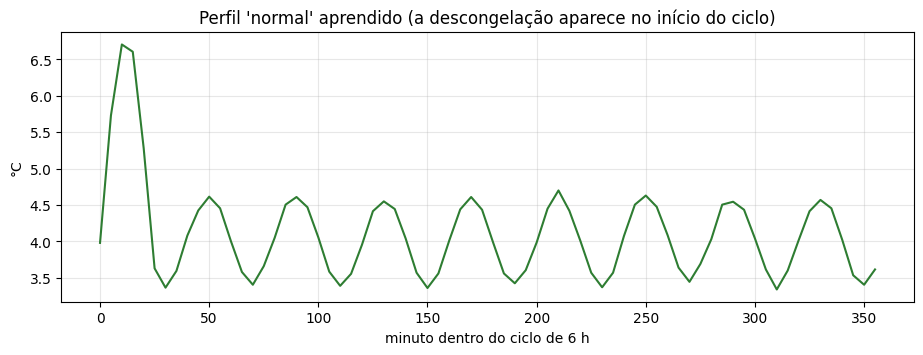

In [7]:
treino = df.timestamp < "2026-09-06"   # primeiros 5 dias (sem avarias)
perfil = df[treino].groupby("minuto_ciclo").temp_c.median()
df["residuo"] = df.temp_c - df.minuto_ciclo.map(perfil)      # desvio face ao normal
df["std_1h"]  = df.temp_c.rolling(12).std()                  # variabilidade na última hora

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(perfil.index, perfil.values, color="#2E7D32")
ax.set_xlabel("minuto dentro do ciclo de 6 h"); ax.set_ylabel("°C")
ax.set_title("Perfil 'normal' aprendido (a descongelação aparece no início do ciclo)")
plt.show()

In [8]:
persistente = (df.residuo > 1.0).astype(int).rolling(8).sum() >= 8   # > 1 °C acima do normal durante 40 min
linha_plana = df.std_1h < 0.03                                         # sensor 'colado'
resultados.append(avaliar(persistente | linha_plana, "B. Perfil esperado + linha plana"))
pd.DataFrame(resultados).set_index("método")

,avarias detetadas,atraso médio (min),falsos alarmes
método,,,
A. Limite fixo > 8 °C,3/4,122,4
A. Limite fixo > 7 °C,3/4,67,13
B. Perfil esperado + linha plana,4/4,98,4


## 5 · Método C — *Isolation Forest* (machine learning não supervisionado)
Aqui **não escrevemos regras**. Damos ao modelo exemplos de funcionamento normal (os primeiros 5 dias) e ele
aprende a reconhecer o que é **invulgar**, olhando para vários sinais ao mesmo tempo:
- o desvio face ao perfil normal, médio da última hora;
- a variabilidade da última hora (em escala logarítmica, para destacar valores quase nulos).

> 🔑 O truque não está no algoritmo, está em **dar-lhe bom contexto** (as variáveis certas).

In [9]:
df["res_1h"]  = df.residuo.rolling(12).mean()
df["log_std"] = np.log10(df.std_1h + 1e-3)
FEATURES = ["res_1h", "log_std"]

d2 = df.dropna(subset=FEATURES).copy()
d2_treino = d2[d2.timestamp < "2026-09-06"]

iso = IsolationForest(n_estimators=300, contamination=0.002, random_state=0).fit(d2_treino[FEATURES])
suspeito = pd.Series(iso.predict(d2[FEATURES]) == -1, index=d2.index).reindex(df.index, fill_value=False)
alerta_iso = suspeito.astype(int).rolling(3).sum() >= 3   # 3 leituras seguidas suspeitas (15 min)

resultados.append(avaliar(alerta_iso, "C. Isolation Forest (+ persistência)"))
pd.DataFrame(resultados).set_index("método")

,avarias detetadas,atraso médio (min),falsos alarmes
método,,,
A. Limite fixo > 8 °C,3/4,122,4
A. Limite fixo > 7 °C,3/4,67,13
B. Perfil esperado + linha plana,4/4,98,4
C. Isolation Forest (+ persistência),4/4,150,1


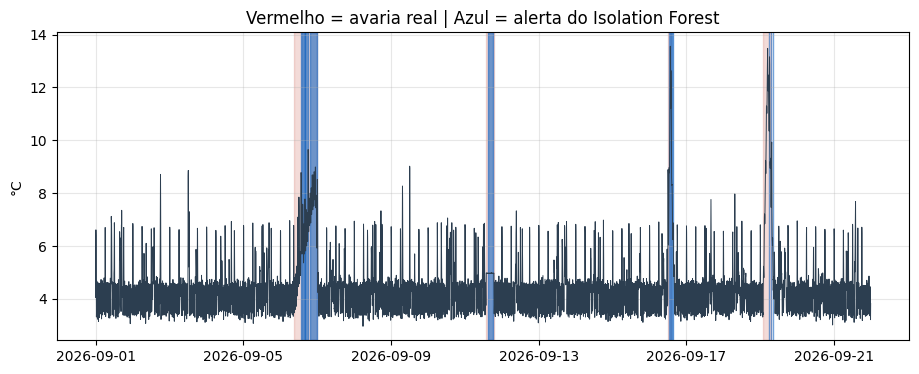

In [10]:
fig, ax = plt.subplots()
ax.plot(df.timestamp, df.temp_c, lw=0.7, color="#2C3E50", label="temperatura")
for ini, fim in reais:
    ax.axvspan(df.timestamp[ini], df.timestamp[fim], color="#C0392B", alpha=0.18)
for ini, fim in segmentos(alerta_iso):
    ax.axvspan(df.timestamp[ini], df.timestamp[fim], color="#1565C0", alpha=0.6)
ax.set_title("Vermelho = avaria real | Azul = alerta do Isolation Forest")
ax.set_ylabel("°C")
plt.show()

## 6 · O que aprendemos
- O **limite fixo** é simples, mas obriga a escolher entre **avisar tarde** ou **ser acordado por falsos alarmes**,
  e não apanha tudo (sensor encravado).
- Um **perfil do que é normal** (contexto) apanha as 4 avarias, mais depressa do que o limite de 8 °C,
  com falsos alarmes semelhantes, e é **explicável**.
- O **machine learning** (Isolation Forest) generaliza o mesmo princípio para vários sinais em simultâneo e teve
  **o menor número de falsos alarmes**, mas, nesta execução, **avisou mais tarde**. Só funciona bem se lhe dermos
  **boas variáveis** e **dados de funcionamento normal** para aprender.
- Nenhum método é perfeito: **o seu critério é afinar** o compromisso entre apanhar cedo e não incomodar.

## 7 · Exercícios para experimentar
1. **Método A:** teste limites de 6, 7,5, 9 °C. Como evoluem atraso e falsos alarmes?
2. **Método B:** altere `1.0` (°C acima do normal) e `8` (nº de leituras seguidas). O que melhora/piora?
3. **Método C:** altere `contamination` (0.002 → 0.01) e a persistência (`>= 3`). Observe a troca entre falsos alarmes e atraso.
4. **E se os primeiros 5 dias tivessem sido anormais?** (Pista: o "normal" que o modelo aprende depende dos dados de treino.)